Energy eigenvalues
 state1: E =  2.024438
 state2: E =  2.097751
 state3: E =  2.219936
 state4: E =  2.390989
 state5: E =  2.610902
 state6: E =  2.879667
 state7: E =  3.197274
 state8: E =  3.563709
 state9: E =  3.978960
 state10: E =  4.443008


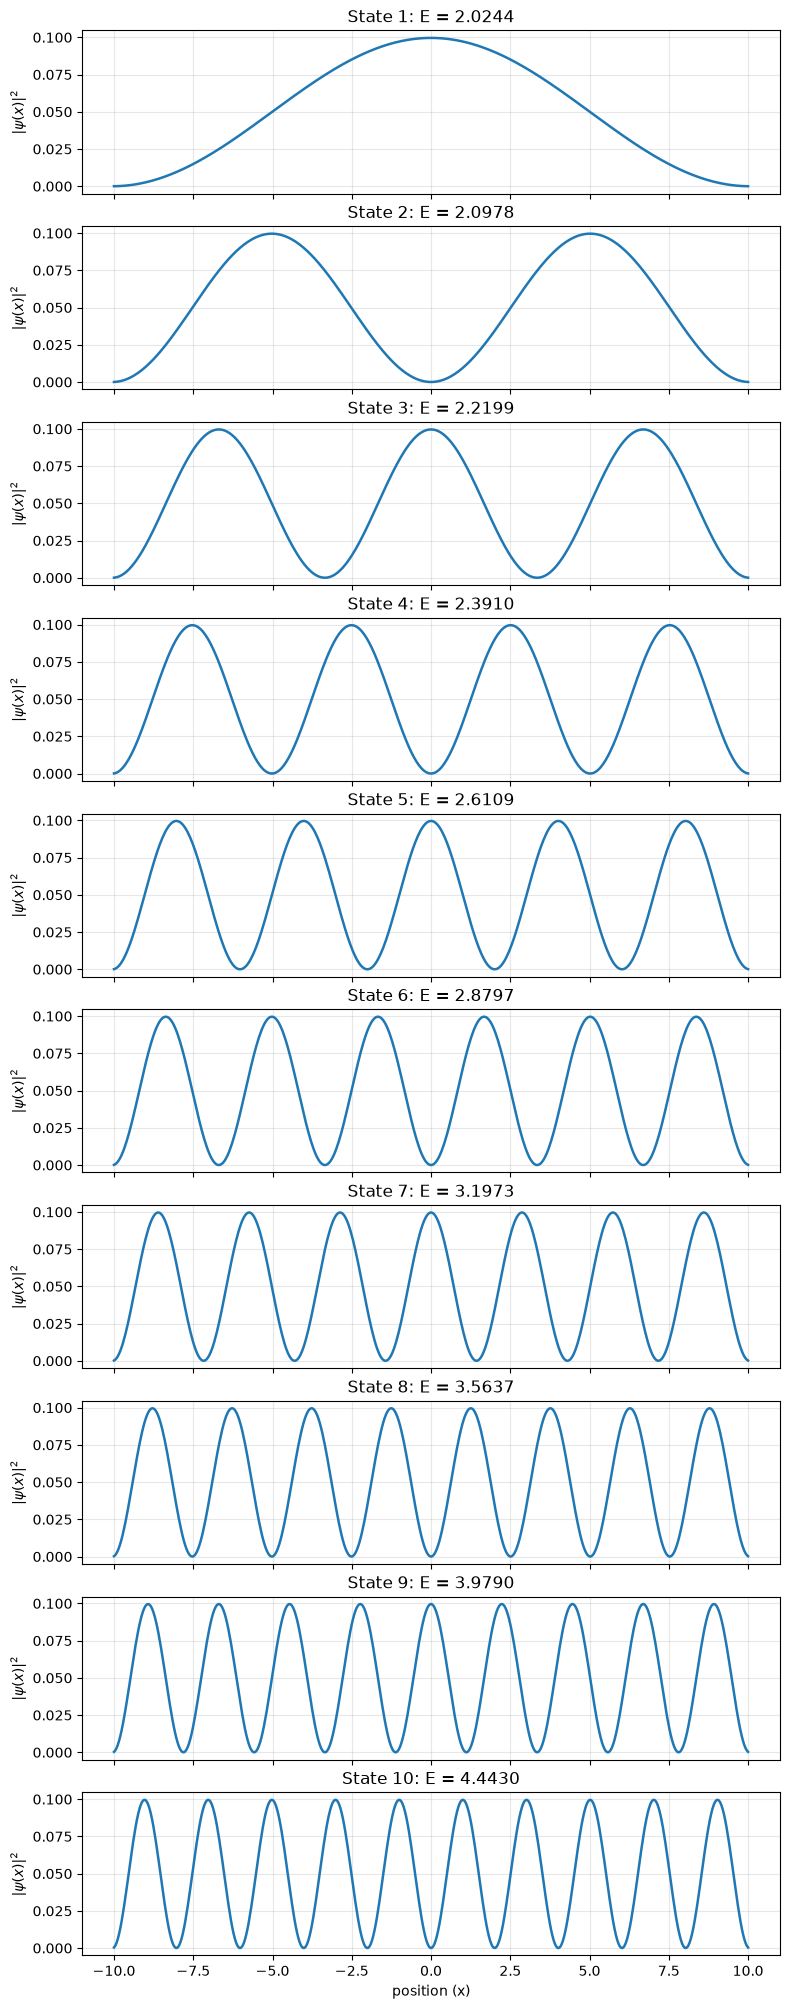

In [ ]:
import numpy as np
import matplotlib.pyplot as plt 
from scipy.sparse.linalg import eigsh

#1.The potential energy function

def free_particle_potential(x, params = None):
    return np.zeros_like(x)
# 2. Solve the 1D Schrödinger equation

def schrodinger1D(xmin, xmax, Nx, Vfun, params = None, neigs = 5):

    x = np.linspace(xmin, xmax, Nx)
    dx = x[1] - x[0]

    V = Vfun(x, params)


    main_diag = 2.0 / dx**2 +V
    off_diag = -1.0 / dx**2 + np.ones(Nx - 1)


    H = diags(
        [off_diag, main_diag, off_diag],
        offsets =[-1, 0 , 1],
        format = 'csc'
    )
    # Calculate the lowest energy eigenvalues and eigenvectors

    eigenvalues, eigenvectors = eigsh(H, k= neigs, which = 'SA')

    indices = np.argsort(eigenvalues)
    eigenvalues = eigenvalues[indices]
    eigenvectors = eigenvectors[:, indices]

    # Normalize eigenfunctions
    for i in range(neigs):
        norm = np.sqrt(np.trapezoid(np.abs(eigenvectors[:, i])**2, x
        ))
        eigenvectors[:, i] /= norm
    return x, eigenvalues, eigenvectors    

# 3. Plot probability densities and energy levels

def plot_wavefunctions(x, eigenvalues, eigenvectors):
    neigs = len(eigenvalues)
    fig, axes = plt.subplots( neigs, 1, figsize = (9, 2.5*neigs), sharex = True)

    if neigs == 1:
        axes = [axes]
    for i , ax in enumerate(axes):
        probability = np.abs(eigenvectors[:, i]**2)
        ax.plot(x, probability, linewidth = 1.8)
        ax.set_ylabel(r'$|\psi(x)|^2$')  
        ax.set_title(f"State {i + 1}: E = {eigenvalues[i]:.4f}") 
        ax.grid(alpha = 0.3)
    axes[-1].set_xlabel("position (x)")
    plt.show()
# Example Parameters:

xmin=-10
xmax=10
Nx = 500
neigs = 10
params = None
x, energies, wavefunctions = schrodinger1D(xmin, xmax, Nx, free_particle_potential, params, neigs)  

print("Energy eigenvalues")

for i , energy in enumerate(energies):
    print(f" state{i +1}: E = {energy: .6f}")

plot_wavefunctions(x, energies, wavefunctions)  
